## Sección 1
##  🧠✨ Proyecto Automatización de la extracción de tarifas ICA

¿De qué manera la implementación de técnicas de Procesamiento de Lenguaje Natural (NLP)
permite automatizar la extracción y estructuración de las tarifas del impuesto ICA a partir de estatutos
municipales, garantizando su consulta en tiempo real para los procesos de facturación electrónica en
Colombia?

Objetivo de la fase de extracción de datos

Construir un sistema capaz de:

Leer automáticamente Estatutos Tributarios Municipales en formato PDF.


1. Extraer el texto normativo.
2. Limpiar y normalizar la información.
3. Identificar artículos relacionados con ICA.
4. Detectar actividades económicas (CIIU).
5. Extraer tarifas asociadas.
6. Estructurar los resultados en una tabla.
7. Preparar los datos para futuras consultas en tiempo real.

---

 🧮 Ejemplo Salida esperada

| Municipio | CIIU | Actividad | Tarifa |
|---|---|---|---|
| Bogotá | 6201 | Desarrollo de software | 9.66 x 1000 |

## Sección 2

## 🔍 Paso 1: Lectura de PDFs

In [ ]:
%pip install pdfplumber "Pillow>=12.2.0,<13"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 44.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 60.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 46.3 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:
import sys
import subprocess

# Asegurar que pdfplumber esté instalado antes de importar
try:
    import pdfplumber
except ModuleNotFoundError:
    print("Instalando pdfplumber...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pdfplumber"])
    import pdfplumber

from google.colab import files
import io

print("Seleccione un archivo PDF")
archivos_subidos = files.upload()

if not archivos_subidos:
    raise ValueError("No se cargó ningún archivo.")

if len(archivos_subidos) > 1:
    raise ValueError("Seleccione solamente un archivo.")

nombre_archivo = next(iter(archivos_subidos))
contenido = archivos_subidos[nombre_archivo]

if not nombre_archivo.lower().endswith('.pdf'):
    raise ValueError("El archivo debe ser un PDF.")

# Leer PDF desde memoria
texto_completo = ""

with pdfplumber.open(io.BytesIO(contenido)) as pdf:
    for pagina in pdf.pages:
        texto = pagina.extract_text()
        if texto:
            texto_completo += texto + "\n"

print("Archivo:", nombre_archivo)
print("Número de caracteres extraídos:", len(texto_completo))

# Mostrar primeros 1000 caracteres
print(texto_completo[:1000])

Seleccione un archivo PDF


Saving San Vicente Ferrer_Acuerdo 081 ESTATUTO TRIBUTARIO_22_diciembre.pdf to San Vicente Ferrer_Acuerdo 081 ESTATUTO TRIBUTARIO_22_diciembre.pdf
Archivo: San Vicente Ferrer_Acuerdo 081 ESTATUTO TRIBUTARIO_22_diciembre.pdf
Número de caracteres extraídos: 514576
CONCEJO MUNICIPAL
SAN VICENTE FERRER-ANTIOQUIA
1
ACUERDO 081
22 DE DICIEMBRE
ESTATUTO DE RENTAS
SAN VICENTE FERRER - ANTIOQUIA
2025
“Trabajamos por construir un Municipio con los mismos derechos y oportunidades para
todos”
Teléfono: 604 8544251 Ext.2544
E-mail: concejo.sanvicente@gmail.com
Dirección: Plazuela Vicente Arbeláez. Cra 28 N° 29-04
Código Postal: 054010
CONCEJO MUNICIPAL
SAN VICENTE FERRER-ANTIOQUIA
2
TABLA DE CONTENIDO
TÍTULO I .............................................................................................................................. 7
PARTE SUSTANTIVA ........................................................................................................ 7
CAPÍTULO 1 ..............................

🔍 Lectura básica

In [ ]:
import pdfplumber
import os

# Usamos el archivo que acabas de subir de forma dinámica
if 'nombre_archivo' in globals() and os.path.exists(nombre_archivo):
    ruta_pdf = nombre_archivo
else:
    # Por defecto busca el primer PDF disponible en el entorno de trabajo
    archivos_pdf = [f for f in os.listdir('.') if f.endswith('.pdf')]
    ruta_pdf = archivos_pdf[0] if archivos_pdf else "estatuto_bogota.pdf"

texto = ""
try:
    with pdfplumber.open(ruta_pdf) as pdf:
        for pagina in pdf.pages:
            texto += pagina.extract_text() + "\n"
    print(f"--- Texto extraído con éxito de: {ruta_pdf} ---\n")
    print(texto[:3000])
except FileNotFoundError:
    print(f"Error: No se encontró el archivo '{ruta_pdf}'. Asegúrate de subir el archivo PDF primero.")

--- Texto extraído con éxito de: San Vicente Ferrer_Acuerdo 081 ESTATUTO TRIBUTARIO_22_diciembre.pdf ---

CONCEJO MUNICIPAL
SAN VICENTE FERRER-ANTIOQUIA
1
ACUERDO 081
22 DE DICIEMBRE
ESTATUTO DE RENTAS
SAN VICENTE FERRER - ANTIOQUIA
2025
“Trabajamos por construir un Municipio con los mismos derechos y oportunidades para
todos”
Teléfono: 604 8544251 Ext.2544
E-mail: concejo.sanvicente@gmail.com
Dirección: Plazuela Vicente Arbeláez. Cra 28 N° 29-04
Código Postal: 054010
CONCEJO MUNICIPAL
SAN VICENTE FERRER-ANTIOQUIA
2
TABLA DE CONTENIDO
TÍTULO I .............................................................................................................................. 7
PARTE SUSTANTIVA ........................................................................................................ 7
CAPÍTULO 1 ....................................................................................................................... 7
NORMAS GENERALES ...............................................

Lectura de múltiples PDFs

```python
import os
import pdfplumber
carpeta = "estatutos"
documentos = []
for archivo in os.listdir(carpeta):

    if archivo.endswith(".pdf"):

        ruta = os.path.join(carpeta, archivo)

        texto = ""

        with pdfplumber.open(ruta) as pdf:

            for pagina in pdf.pages:
                texto += pagina.extract_text() + "\n"

        documentos.append({
            "municipio": archivo.replace(".pdf",""),
            "texto": texto
        })
```

## 🎯 Paso 2: Crear DataFrame

In [ ]:
import pandas as pd
# Como estamos procesando un único archivo subido, creamos la lista de documentos a partir de él
documentos = [{
    "municipio": "San Vicente Ferrer",
    "texto": texto
}]

df = pd.DataFrame(documentos)
df.head()

,municipio,texto
0,San Vicente Ferrer,CONCEJO MUNICIPAL\nSAN VICENTE FERRER-ANTIOQUI...


## Sección 3

## 🎯 Paso 3: Preprocesamiento NLP

Instalar NLTK

In [ ]:
!pip install nltk

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

## 🧠 Tokenización

In [ ]:
import nltk
from nltk.tokenize import word_tokenize

# Descargar el recurso requerido por las versiones recientes de NLTK
nltk.download('punkt_tab')

texto = df.loc[0,"texto"]
tokens = word_tokenize(texto)
tokens[:30]

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


['CONCEJO',
 'MUNICIPAL',
 'SAN',
 'VICENTE',
 'FERRER-ANTIOQUIA',
 '1',
 'ACUERDO',
 '081',
 '22',
 'DE',
 'DICIEMBRE',
 'ESTATUTO',
 'DE',
 'RENTAS',
 'SAN',
 'VICENTE',
 'FERRER',
 '-',
 'ANTIOQUIA',
 '2025',
 '“',
 'Trabajamos',
 'por',
 'construir',
 'un',
 'Municipio',
 'con',
 'los',
 'mismos',
 'derechos']


## 🧠 Lowercasing

In [ ]:
tokens = [t.lower() for t in tokens]

## 🧠 Eliminar stopwords

In [ ]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words("spanish"))

tokens_limpios = [
    t for t in tokens
    if t.isalpha() and t not in stop_words
]

## 🎯 Paso 4: Lematización con spaCy

In [ ]:
!pip install spacy

In [ ]:
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 26.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## 🧠 Procesamiento

In [ ]:
import spacy
nlp = spacy.load("es_core_news_sm")
doc = nlp(" ".join(tokens_limpios))
lemmas = [token.lemma_ for token in doc]

## Sección 4

## Paso 5: Análisis exploratorio del corpus

In [ ]:
from collections import Counter
frecuencias = Counter(lemmas)
frecuencias.most_common(20)

[('artículo', 677),
 ('vicente', 573),
 ('impuesto', 537),
 ('municipio', 516),
 ('municipal', 415),
 ('san', 362),
 ('actividad', 325),
 ('mismo', 300),
 ('dirección', 276),
 ('sanción', 266),
 ('deber', 265),
 ('declaración', 258),
 ('código', 254),
 ('derecho', 251),
 ('comercio', 236),
 ('ley', 236),
 ('tributario', 234),
 ('concejo', 224),
 ('teléfono', 223),
 ('oportunidad', 219)]

## 🧠 Gráfico

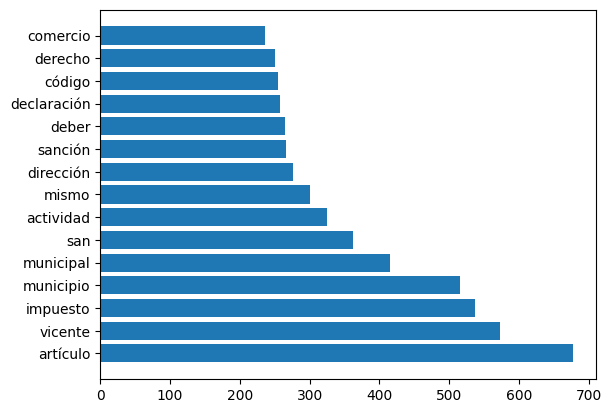

In [ ]:
import matplotlib.pyplot as plt
top = frecuencias.most_common(15)
palabras = [x[0] for x in top]
conteo = [x[1] for x in top]
plt.barh(palabras,conteo)
plt.show()

## 🎯 Paso 6: TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizador = TfidfVectorizer(
    stop_words=list(stop_words),
    max_features=300
)
X = vectorizador.fit_transform(df["texto"])

## Términos más importantes

In [ ]:
import numpy as np
promedio_tfidf = np.asarray(X.mean(axis=0)).ravel()
indices = promedio_tfidf.argsort()[::-1]
vocabulario = vectorizador.get_feature_names_out()
for idx in indices[:30]:
    print(vocabulario[idx])

artículo
vicente
municipio
concejo
impuesto
municipal
san
ferrer
antioquia
dirección
código
actividades
comercio
derechos
ley
teléfono
29
mismos
28
04
com
construir
plazuela
oportunidades
postal
604
8544251
2544
mail
cra


## Sección 5

## 🎯 Paso 7: POS Tagging



In [ ]:
doc = nlp(texto[:10000])
for token in doc[:50]:
    print(token.text,
          token.pos_,
          token.dep_)

CONCEJO PROPN nsubj
MUNICIPAL PROPN flat

 SPACE dep
SAN PROPN flat
VICENTE PROPN flat
FERRER-ANTIOQUIA PROPN flat

 SPACE dep
1 NUM nummod

 SPACE dep
ACUERDO PROPN appos
081 NUM nummod

 SPACE dep
22 NUM compound
DE ADP case
DICIEMBRE PROPN nmod

 SPACE dep
ESTATUTO NOUN flat
DE ADP case
RENTAS PROPN nmod

 SPACE dep
SAN PROPN appos
VICENTE PROPN flat
FERRER PROPN flat
- PUNCT punct
ANTIOQUIA PROPN appos

 SPACE dep
2025 NOUN appos

 SPACE dep
“ PROPN flat
Trabajamos VERB ROOT
por ADP mark
construir VERB xcomp
un DET det
Municipio NOUN obj
con ADP case
los DET det
mismos DET det
derechos NOUN obl
y CCONJ cc
oportunidades NOUN conj
para ADP case

 SPACE dep
todos DET det
” PUNCT punct

 SPACE dep
Teléfono NOUN nmod
: PUNCT punct
604 NUM nummod
8544251 NOUN appos
Ext.2544 PROPN appos


## Sección 6

## 🎯 Paso 8: Extracción de artículos ICA

In [ ]:
import re

# Buscar encabezados al inicio de una línea.
# Acepta Artículo, ARTÍCULO y ARTICULO.
patron_articulos = r'^[ \t]*art[ií]culo[ \t]+\d+\b'

encabezados = list(
    re.finditer(
        patron_articulos,
        texto,
        flags=re.IGNORECASE | re.MULTILINE
    )
)

# Conservar cada artículo hasta el siguiente encabezado.
articulos = []

for i, encabezado in enumerate(encabezados):
    inicio = encabezado.start()

    fin = (
        encabezados[i + 1].start()
        if i + 1 < len(encabezados)
        else len(texto)
    )

    articulos.append(texto[inicio:fin].strip())

print('Fragmentos candidatos a artículos:', len(articulos))

if articulos:
    print('\nVista previa del primer fragmento:')
    print(articulos[0][:1000])
else:
    print(
        'No se encontraron encabezados. '
        'Revisa cómo aparecen los artículos en el texto extraído.'
    )

488


## 🎯 Paso 9: Identificación de artículos relacionados con ICA

In [ ]:
import re

# Conservar una lista de términos para las etapas posteriores.
keywords = [
    "ica",
    "reteica",
    "industria y comercio",
    "ciiu"
]

# Buscar siglas completas o la expresión industria y comercio.
patron_contexto_ica = re.compile(
    r'\b(?:ica|reteica|ciiu)\b'
    r'|\bindustria\s+y\s+comercio\b',
    flags=re.IGNORECASE
)

articulos_ica = []

for articulo in articulos:
    if patron_contexto_ica.search(articulo):
        articulos_ica.append(articulo)

print('Fragmentos revisados:', len(articulos))
print('Fragmentos candidatos relacionados con ICA:', len(articulos_ica))

if articulos_ica:
    print('\nVista previa del primer candidato:')
    print(articulos_ica[0][:1000])
else:
    print('No se encontraron coincidencias con el filtro.')

##  🎯 Paso 10: Extracción automática de tarifas

In [ ]:
import re

# Buscar valores con unidad explícita por mil.
# Ejemplos: 7 por mil, 9,66 x 1000, 5 × 1.000, 7‰.
patron_tarifa = re.compile(
    r'(?<![\w.,])'
    r'\d+(?:[.,]\d+)?'
    r'\s*'
    r'(?:[x×]\s*1[.\s]?000|por\s+mil|‰)'
    r'(?!\w)',
    flags=re.IGNORECASE
)

total_tarifas = 0

for numero, articulo in enumerate(articulos_ica, start=1):
    tarifas = re.findall(patron_tarifa, articulo)

    if tarifas:
        total_tarifas += len(tarifas)

        print(f'\nFragmento candidato {numero}')
        print('Inicio:', articulo[:100].replace('\n', ' '))
        print('Tarifas candidatas:', tarifas)

print('\nTotal de apariciones encontradas:', total_tarifas)

if total_tarifas == 0:
    print(
        'No se encontraron valores con unidad por mil explícita. '
        'Revisa las tablas y el texto extraído.'
    )

[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
['33 x 1000']
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
['10 x 1000']
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
['8 x 1000']
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]


## 🎯 Paso 11: Extracción de códigos CIIU

In [ ]:
patron_ciiu = r"\b\d{4}\b"
re.findall(patron_ciiu, articulo)

['2019',
 '2020',
 '2021',
 '2022',
 '2023',
 '2025',
 '2544',
 '2025',
 '2025',
 '2025',
 '1333',
 '1986',
 '1994',
 '2025',
 '2544',
 '2025',
 '2544']

## 🎯 Paso 12: Reconocimiento de entidades con spaCy

In [ ]:
doc = nlp(texto)
for ent in doc.ents:

    print(
        ent.text,
        ent.label_
    )

CONCEJO MUNICIPAL
SAN VICENTE FERRER-ANTIOQUIA LOC
DICIEMBRE ORG
ESTATUTO MISC
RENTAS
SAN VICENTE FERRER MISC
ANTIOQUIA ORG
Municipio ORG
Teléfono LOC
Ext.2544
E-mail: concejo.sanvicente@gmail.com
Dirección: Plazuela Vicente Arbeláez MISC
Cra 28 N MISC
Código Postal LOC
CONCEJO MUNICIPAL
SAN VICENTE FERRER-ANTIOQUIA LOC
TABLA ORG
CONTENIDO ORG
TÍTULO I MISC
........................................................................................................ ORG
CAPÍTULO ORG
..................................................................................................... 7 MISC
CAPÍTULO MISC
CAPÍTULO MISC
INDUSTRIA ORG
SISTEMA MISC
RÉGIMEN SIMPLE MISC
RETENCIÓN MISC
AUTORRETENCIÓN MISC
CAPÍTULO MISC
..................................................................................................................... 95
IMPUESTO MISC
AVISOS MISC
TABLEROS MISC
CAPÍTULO MISC
ACTIVIDAD BOMBERIL MISC
CAPÍTULO MISC
PUBLICIDAD ORG
VISUAL MISC
AVISOS ......................................

## Sección 7

## 🎯 Paso 13: Construcción de dataset estructurado

In [ ]:
registros = []

for articulo in articulos_ica:

    tarifas = re.findall(
        patron_tarifa,
        articulo
    )

    ciius = re.findall(
        patron_ciiu,
        articulo
    )

    for tarifa in tarifas:

        registros.append({
            "municipio": "Bogotá",
            "articulo": articulo[:50],
            "ciiu": ciius,
            "tarifa": tarifa
        })

## 📔 DataFrame final

In [ ]:
df_ica = pd.DataFrame(registros)
df_ica.head()

,municipio,articulo,ciiu,tarifa
0,Bogotá,Artículo 54 Ley 2010 de 2019.\nEn los demás ca...,"[2010, 2019, 1607, 2012, 2544, 1981, 2024, 198...",33 x 1000
1,Bogotá,Artículo 111. BASE Y TARIFA PARA LA RETENCIÓN ...,"[1000, 2544]",10 x 1000
2,Bogotá,Artículo 234. TARIFA; Es el ocho por mil (8 x ...,[1000],8 x 1000


## Sección 8

##  📚  Paso 14: Clasificación supervisada

Vectorización

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Usamos la lista de artículos que definimos en los pasos anteriores
X = vectorizador.fit_transform(articulos)

Modelo

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
import numpy as np

# Creamos etiquetas ficticias (y) para ilustrar el entrenamiento.
# Por ejemplo, 1 si el artículo contiene palabras clave de ICA, 0 si no.
y = np.array([1 if any(k in art.lower() for k in keywords) else 0 for art in articulos])

# Dividimos los datos en entrenamiento (train) y prueba (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializamos y entrenamos el modelo Naive Bayes
modelo = MultinomialNB()
modelo.fit(X_train, y_train)
print("Modelo entrenado exitosamente con X_train de tamaño:", X_train.shape)

Modelo entrenado exitosamente con X_train de tamaño: (390, 300)


##  📚  Paso 15: Clustering

In [ ]:
from sklearn.cluster import KMeans
modelo = KMeans(n_clusters=5)
clusters = modelo.fit_predict(X)

##  📚  Paso 16: Word Embeddings

In [ ]:
import sys
import subprocess
from nltk.tokenize import word_tokenize

# 1. Asegurar la instalación de gensim
try:
    from gensim.models import Word2Vec
except ModuleNotFoundError:
    print("Instalando gensim...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gensim"])
    from gensim.models import Word2Vec

# 2. Definir corpus_tokenizado a partir de la lista de artículos existente
corpus_tokenizado = [word_tokenize(art.lower()) for art in articulos]

# 3. Entrenar el modelo Word2Vec
modelo_w2v = Word2Vec(
    sentences=corpus_tokenizado,
    vector_size=100,
    window=5,
    min_count=2
)
print("Modelo Word2Vec entrenado con éxito.")

Instalando gensim...
Modelo Word2Vec entrenado con éxito.


Similitud

In [ ]:
modelo_w2v.wv.most_similar(
    "tarifa"
)

[('tributo', 0.9961544871330261),
 ('capítulo', 0.9959201216697693),
 ('actividad', 0.995624840259552),
 ('vigencia', 0.9953024983406067),
 ('tarifas', 0.9952530264854431),
 ('hasta', 0.995246171951294),
 ('•', 0.9944983124732971),
 ('participación', 0.9943537712097168),
 ('hace', 0.9942317605018616),
 ('documento', 0.9940874576568604)]

##  📚  Paso 17: Visualización UMAP o t-SNE

In [ ]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2)

embeddings_2d = tsne.fit_transform(
    modelo_w2v.wv.vectors
)

Visualizar agrupaciones:

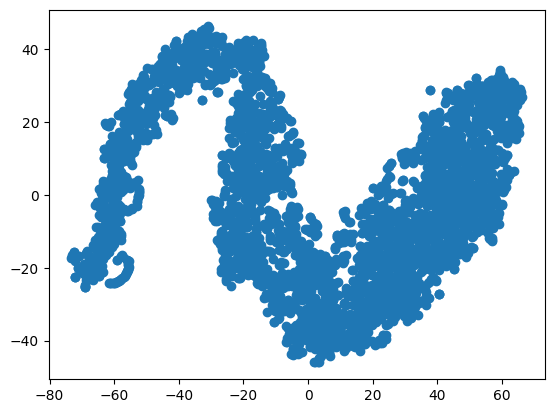

In [ ]:
plt.scatter(
    embeddings_2d[:,0],
    embeddings_2d[:,1]
)